In [ ]:
# Core dependencies
import math 
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
np.random.seed(2025701040)

n = 11001
a, b = 3.5, 2.0
sigma = 0.1

# Generate 1D data with Gaussian noise
x_clean = np.random.uniform(0, 3, n)
noise = np.random.normal(0, sigma, n)

y_clean = a * x_clean + b + noise

y_org = a * x_clean + b # this is the ideal line of we do not add the elipson noise to the actual line equation
y_org

array([ 5.06733867,  4.01954011, 11.1813811 , ...,  6.59109791,
        6.6943093 ,  3.84213881], shape=(11001,))

In [48]:
noise, noise.min(), noise.mean() , noise.max()

(array([ 0.02400787,  0.20505595, -0.05088474, ..., -0.06411895,
        -0.01349315,  0.03156491], shape=(11001,)),
 np.float64(-0.4065067377709758),
 np.float64(0.0014122861316711313),
 np.float64(0.4189450444235675))

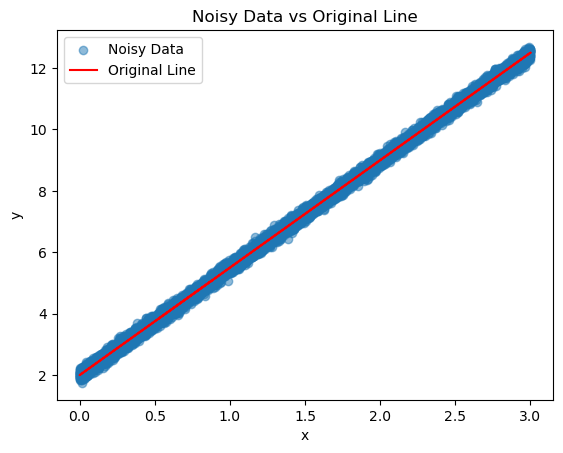

In [49]:
plt.scatter(x_clean, y_clean, alpha=0.5, label='Noisy Data')
plt.plot(x_clean, y_org, color='red', label='Original Line')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Noisy Data vs Original Line')
plt.legend()
plt.show()

### Data Generation (1D)
- Number of samples: $n = 11001$
- True parameters: $a = 3.5$, $b = 2.0$
- Noise model: $\epsilon \sim \mathcal{N}(0, 0.1^2)$
- Rationale: Gaussian noise is a standard assumption in many regression settings.

In [ ]:
# Create a correlated feature
epsilon = np.random.normal(0, 0.01, n) 
x1 = 2*x_clean + epsilon  

### Correlated Feature Construction
A second feature is created as a linear function of $x$ with small Gaussian perturbation to induce high correlation between features.

In [ ]:
# Stack correlated features
x_corr = np.column_stack([x_clean, x1]) # this is the total feature matrix with 2 features x and x1 which is our correlated feature dataset
x_corr.shape

(11001, 2)

In [ ]:
# Generate correlated target with noise
real_coef = np.array([2.0, 3.0])
noise = np.random.normal(0, 0.1, n)

y_corr_org = x_corr @ real_coef  # this is the ideal line of we do not add the elipson noise to the actual line equation
y_corr = x_corr @ real_coef + noise 
y_corr

array([ 6.91172935,  4.49027417, 21.03133623, ..., 10.53478498,
       10.81794916,  4.41913896], shape=(11001,))

In [53]:
y_corr_org, y_corr

(array([ 6.99489591,  4.60242551, 21.00135453, ..., 10.53756637,
        10.73625596,  4.28127286], shape=(11001,)),
 array([ 6.91172935,  4.49027417, 21.03133623, ..., 10.53478498,
        10.81794916,  4.41913896], shape=(11001,)))

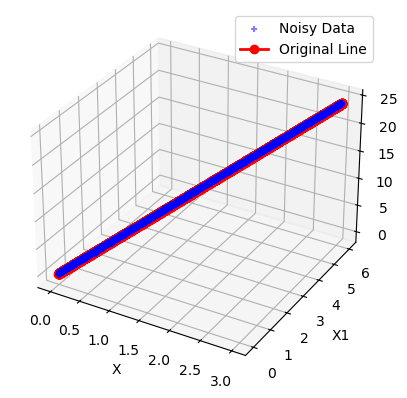

In [54]:
fig = plt.figure()
ax = fig.add_subplot(projection='3d')

ax.scatter(x_clean, x1, y_corr, c='blue', marker='+', label='Noisy Data', alpha=0.5)

ax.plot(x_clean, x1, y_corr_org, color='red',marker='o' ,label='Original Line', linewidth=2)

ax.set_xlabel('X'); ax.set_ylabel('X1'); ax.set_zlabel('y1')

ax.legend()

plt.show()


In [ ]:
# Conditioning diagnostics
XtX = x_corr.T @ x_corr

eigenvalues = np.linalg.eigvals(XtX)
condition_number = np.linalg.cond(XtX)
print("Eigenvalues of X^T X:", eigenvalues)
print("Condition number of X^T X:", condition_number)

Eigenvalues of X^T X: [2.20374901e-01 1.65430171e+05]
Condition number of X^T X: 750676.0966450969


### Correlated-Feature Diagnostics
The printed eigenvalues and condition number of $X^T X$ indicate the degree of ill-conditioning in the correlated-feature design matrix.

In [56]:
y_clean, y_clean.min(), y_clean.max(), y_clean.mean()

(array([ 5.09134653,  4.22459606, 11.13049636, ...,  6.52697896,
         6.68081616,  3.87370372], shape=(11001,)),
 np.float64(1.747078879737451),
 np.float64(12.687966255977354),
 np.float64(7.252011839127369))

In [ ]:
# Sample outlier indices and magnitudes
outlier_percent = 0.10 # 10% outliers
num_outliers = int(n * outlier_percent)
outlier_indices = np.random.choice(n, num_outliers, replace=False)
outlier_add = np.random.normal(6, 3, num_outliers)

In [58]:
outlier_add, outlier_add.min(), outlier_add.max(), outlier_add.mean()

(array([ 3.07407079,  4.69636543,  9.49739508, ..., 10.57747403,
         5.76652458,  6.53426603], shape=(1100,)),
 np.float64(-4.672128866049928),
 np.float64(14.753067018101067),
 np.float64(6.015293879167813))

In [59]:
type(outlier_indices)

numpy.ndarray

In [ ]:
# Extra extreme outlier indices
random_extreme_indices = np.random.choice(n,110*5)
random_extreme_indices

array([ 6503,  2251,  1684,  2735, 10280,  7758,  6747, 10028, 10943,
        6906,  1177,  8099,   735,  1753, 10359,  3292,  7494,  9382,
        8384, 10186,  6581,  1852,  4126,  3556,  6920,   840,  8803,
         124,  4891,  5969,   935,  2384,  4226,  8227,   949,  2882,
        8181,   572,  3913,  7942,  7205,  5971,  8049,  9171,  2800,
        8261,  8933,   867,  5002,  6431,  8443,  5187,  5467,  8527,
        7837,   583,  3592,  8822,  7354,  3915,  3164,  1948,  1291,
        8556,   491,  6448,  5495,  2873,  6649,   892,  1333,  7239,
        6538,  7696,  6864, 10746,  2185,  4656,  3525,  8712, 10332,
         234,  4130,  9721,  7758, 10300,  8533,  9883,  4354,  2704,
        9324,   804,  1475,   857,  9015,  4993,  7391,  3554,  7456,
        4018,  2013,  4486,  4143,   418,  6392, 10094,  1193,  2409,
         787,  9466,  1138,  6450,  4493, 10579,  2105,  5100,   858,
        5076,  6641,  5510,  4298,  4762,  6738,  6651,  8970,  2726,
        5346,  9539,

In [ ]:
# Sample extreme outlier values
extreme_outliers = np.random.choice([10, 12, 15, 19,25, 50,100],110*5, p=[0.4,0.1,0.1,0.1,0.1,0.1,0.1])
extreme_outliers

array([ 12,  10,  50,  25,  10,  50, 100, 100,  10,  10,  19,  19,  10,
        50,  12,  10,  10,  10,  10,  10,  50, 100,  10,  10,  50,  10,
        15,  10,  50,  15,  19,  10,  50,  25,  50,  10,  50,  50,  12,
        10,  10,  10,  15,  50,  15,  50,  10,  15,  10,  12,  19,  10,
       100,  10,  10,  50,  15,  10,  50,  50,  10, 100,  10,  10,  25,
        50,  19,  19, 100,  10,  50,  10,  15,  10,  15,  50,  10,  15,
        50,  12,  10,  10, 100,  10,  19,  15,  19, 100, 100,  15,  10,
       100,  10,  10,  10,  10,  10,  50,  10,  10,  12, 100,  10,  15,
        25,  10,  50,  10,  15,  12,  10,  15,  50,  50,  25,  50,  15,
        25,  10,  10,  12,  12,  12,  10,  25, 100,  12,  25,  10,  10,
        25,  10,  15,  10, 100, 100,  15,  10, 100,  19, 100,  12,  10,
        12,  50,  50,  15,  15,  10,  10,  10,  50,  10,  10, 100,  10,
        19,  15,  10,  15,  50,  10,  10,  19,  50,  10,  10,  15,  10,
        15,  10,  12,  50,  10,  19,  25,  10,  10, 100,  15,  1

In [62]:
y_outliers = y_clean.copy()

In [ ]:
# Inject outliers
y_outliers[outlier_indices] += outlier_add  # adding large noise to create outliers
y_outliers[random_extreme_indices] += extreme_outliers

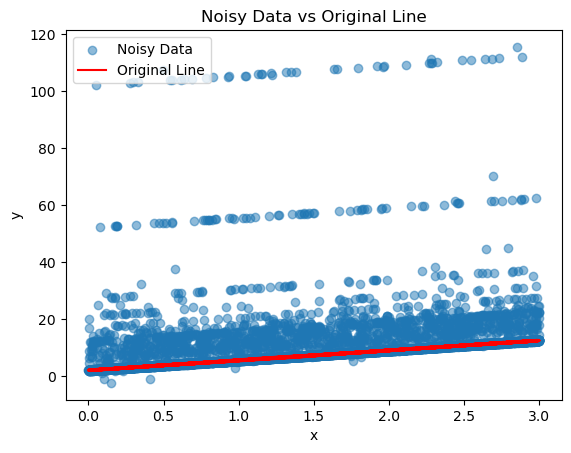

In [64]:
plt.scatter(x_clean, y_outliers, alpha=0.5, label='Noisy Data')
plt.plot(x_clean, y_clean, color='red', label='Original Line')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Noisy Data vs Original Line')
plt.legend()
plt.show()

### Outlier Injection Strategy
- Add moderate outliers to 10% of points using Gaussian noise with mean 6 and std 3.
- Add additional extreme outliers (about 5%) from a fixed high-value set.
- Purpose: stress-test robustness of linear estimators under heavy-tailed corruption.

## Part B - Implementation from Scratch

### Tasks
- B.1 Closed-form ordinary least squares (OLS). [1 mark]
- B.2 Gradient descent for OLS (MSE objective). [1 mark]
- B.3 Ridge regression (closed-form and gradient descent). [1.5 marks]
- B.4 Lasso regression via sub-gradient descent. [1.5 marks]
- B.5 Weighted least squares (closed-form). [1 mark]

In [ ]:
# Closed-form and iterative solvers
def closed_form_solution(X, y): #ols solution
    
    return np.linalg.pinv(X.T @ X) @ X.T @ y

def gradient_descent(X, y, learning_rate=0.01, max_iterations=1000):
    n_samples, n_features = X.shape
    w = np.zeros(n_features)
    loss = []
    
    for i in range(max_iterations):
        predictions = X @ w
        errors = predictions - y
        gradient = (2/n_samples) * (X.T @ errors)
        w -= learning_rate * gradient

        loss.append(np.mean(errors**2))
        if i % 10 == 0:
            print(f"Iteration {i}, Loss: {np.mean(errors**2)}, w: {w}")

        
    return w, loss

def ridge_regression(X, y, lambda_=1.0):
    n_features = X.shape[1]
    I = np.eye(n_features)
    return np.linalg.inv(X.T @ X + lambda_ * I) @ X.T @ y

def ridge_regression_gradient_descent(X, y, alpha=1.0, learning_rate=0.01, max_iterations=1000):
    n_samples, n_features = X.shape
    w = np.zeros(n_features)
    loss = []
    
    for i in range(max_iterations):
        predictions = X @ w
        errors = predictions - y
        gradient = (2/n_samples) * (X.T @ errors) + 2 * alpha * w
        w -= learning_rate * gradient
        loss.append(np.mean(errors**2) + alpha * np.sum(w**2))
        if i % 10 == 0:
            print(f"Iteration {i}, Loss: {np.mean(errors**2) + alpha * np.sum(w**2)}, w: {w}")
        
    return w, loss 

def lasso_regression_sub_gradient(X, y, alpha=1.0, learning_rate=0.01, max_iterations=1000):
    n_samples, n_features = X.shape
    w = np.zeros(n_features)
    loss = []
    
    for i in range(max_iterations):
        predictions = X @ w
        errors = predictions - y
        gradient = (2/n_samples) * (X.T @ errors) + alpha * np.sign(w)
        w -= learning_rate * gradient

        loss.append(np.mean(errors**2) + alpha * np.sum(np.abs(w)))
        if i % 10 == 0:
            print(f"Iteration {i}, Loss: {np.mean(errors**2) + alpha * np.sum(np.abs(w))}, w: {w}")
        
    return w

def weighted_least_squares(X, y, weights):
    W = weights
    X_weighted = X * W[:, None]
    return np.linalg.pinv(X.T @ X_weighted) @ X.T @ (W * y)

In [ ]:
# Add bias term
x_bias = np.column_stack([np.ones(n), x_clean])

## Part C - Gradient Descent Analysis [6 marks]
Using the clean dataset:
- C.1 Train with at least three learning rates. Plot loss vs. iteration for each. Show one rate that converges, one that oscillates, and one that diverges. [2.5 marks]
- C.2 Relate convergence behavior to the eigenvalues of $X^T X$. Verify the condition $\eta < \frac{2}{\lambda_{max}}$ for convergence. [2 marks]
- C.3 Written (5-8 sentences): Explain theoretically why the maximum eigenvalue of $X^T X$ governs the convergence bound. [1.5 marks]

In [67]:
final_w, loss = gradient_descent(x_bias, y_clean, learning_rate=0.01, max_iterations=100)

Iteration 0, Loss: 61.87649578556803, w: [0.14504024 0.27058132]
Iteration 10, Loss: 12.695484463641822, w: [1.10885914 2.06556675]
Iteration 20, Loss: 2.6125095503813984, w: [1.54728769 2.87722823]
Iteration 30, Loss: 0.5452157981865119, w: [1.74774806 3.2436972 ]
Iteration 40, Loss: 0.12126446923335504, w: [1.8403839  3.40863008]
Iteration 50, Loss: 0.0342320319430063, w: [1.88412534 3.48234936]
Iteration 60, Loss: 0.016281798374456303, w: [1.90565792 3.51480594]
Iteration 70, Loss: 0.012502644981060327, w: [1.91706721 3.52861539]
Iteration 80, Loss: 0.011636358329954506, w: [1.92382802 3.53401631]
Iteration 90, Loss: 0.011374258821897546, w: [1.92842179 3.53564322]


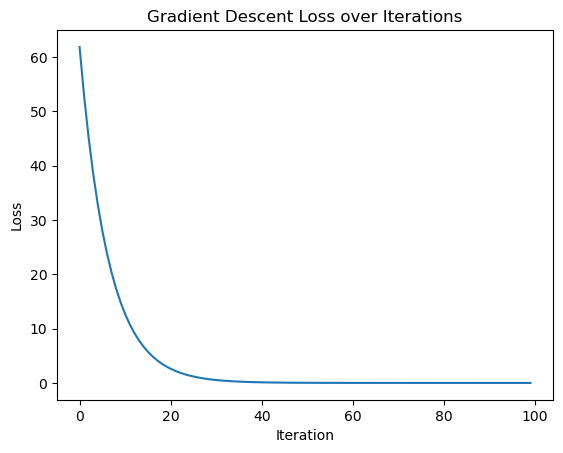

In [68]:
plt.plot(loss)
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.title('Gradient Descent Loss over Iterations')
plt.show()

Iteration 0, Loss: 61.87649578556803, w: [1.45040237 2.70581325]
Iteration 10, Loss: 0.01121679202823894, w: [1.93555349 3.53520986]
Iteration 20, Loss: 0.01055443365767223, w: [1.95742504 3.52352897]
Iteration 30, Loss: 0.010260157124650194, w: [1.97200329 3.51574277]
Iteration 40, Loss: 0.010129414184661699, w: [1.9817204 3.5105529]
Iteration 50, Loss: 0.010071326928497264, w: [1.98819731 3.5070936 ]
Iteration 60, Loss: 0.010045519574547522, w: [1.99251448 3.50478781]
Iteration 70, Loss: 0.0100340537288205, w: [1.99539209 3.50325089]
Iteration 80, Loss: 0.010028959614232393, w: [1.99731015 3.50222646]
Iteration 90, Loss: 0.010026696370503619, w: [1.99858862 3.50154363]


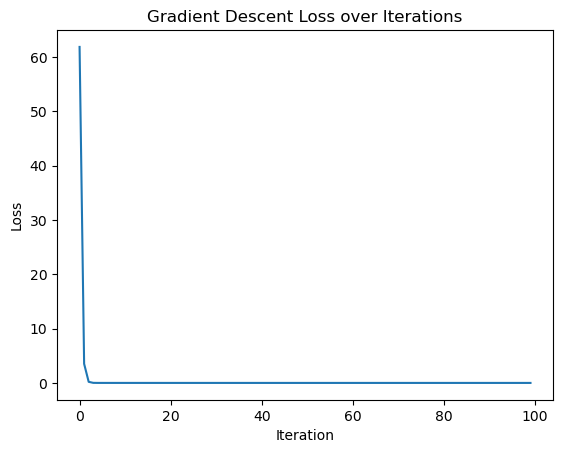

In [69]:
final_w1, loss1 = gradient_descent(x_bias, y_clean, learning_rate=0.1, max_iterations=100)
plt.plot(loss1)
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.title('Gradient Descent Loss over Iterations')
plt.show()

Iteration 0, Loss: 61.87649578556803, w: [0.01450402 0.02705813]
Iteration 10, Loss: 53.10328034507562, w: [0.15362011 0.2865497 ]
Iteration 20, Loss: 45.57423292323552, w: [0.28252319 0.52692313]
Iteration 30, Loss: 39.11291223563922, w: [0.40196499 0.74958591]
Iteration 40, Loss: 33.56789896447038, w: [0.51264193 0.9558419 ]
Iteration 50, Loss: 28.80924727596875, w: [0.61519913 1.14689898]
Iteration 60, Loss: 24.725439564859457, w: [0.71023423 1.32387612]
Iteration 70, Loss: 21.220773060769424, w: [0.79830087 1.4878099 ]
Iteration 80, Loss: 18.213117052255253, w: [0.87991196 1.63966058]
Iteration 90, Loss: 15.63198816941955, w: [0.9555426  1.78031775]


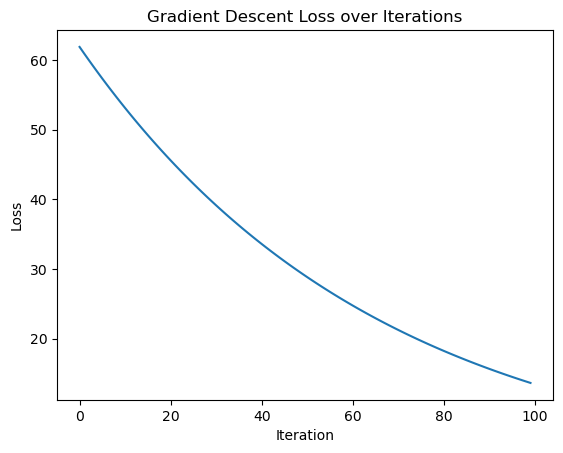

In [70]:
final_w1, loss2 = gradient_descent(x_bias, y_clean, learning_rate=0.001, max_iterations=100)
plt.plot(loss2)
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.title('Gradient Descent Loss over Iterations')
plt.show()

Iteration 0, Loss: 61.87649578556803, w: [0.04351207 0.0811744 ]
Iteration 10, Loss: 38.97420691616879, w: [0.42766133 0.79750275]
Iteration 20, Loss: 24.550416461519823, w: [0.73275716 1.36585252]
Iteration 30, Loss: 15.466350394828192, w: [0.97511364 1.81676843]
Iteration 40, Loss: 9.745221568254761, w: [1.16767761 2.1744907 ]
Iteration 50, Loss: 6.142057451832351, w: [1.32072365 2.45825624]
Iteration 60, Loss: 3.8727793903414636, w: [1.4424057  2.68333141]
Iteration 70, Loss: 2.4435778194818374, w: [1.53919471 2.8618315 ]
Iteration 80, Loss: 1.5434534699111595, w: [1.61622604 3.00337118]
Iteration 90, Loss: 0.9765402539280024, w: [1.67757512 3.11558057]


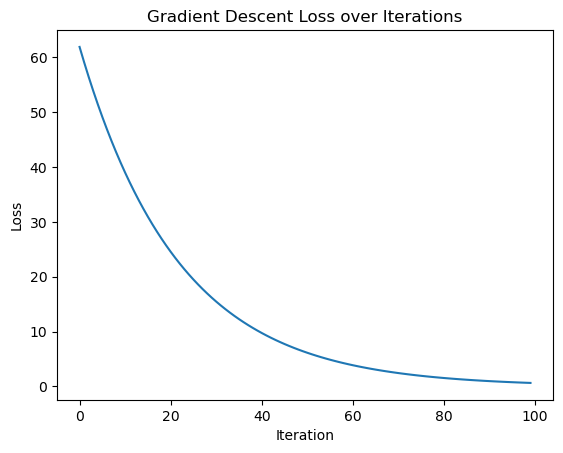

In [71]:
final_w1, loss3 = gradient_descent(x_bias, y_clean, learning_rate=0.003, max_iterations=100)
plt.plot(loss3)
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.title('Gradient Descent Loss over Iterations')
plt.show()

Iteration 0, Loss: 61.87649578556803, w: [4.3512071  8.11743974]
Iteration 10, Loss: 9362.47370691881, w: [31.9966707  59.72238203]
Iteration 20, Loss: 1416914.8943052622, w: [371.31176363 694.98470751]
Iteration 30, Loss: 214435847.54016548, w: [4545.35737648 8510.11850001]
Iteration 40, Loss: 32452713438.661446, w: [ 55894.53388576 104652.16868125]
Iteration 50, Loss: 4911392482468.218, w: [ 687593.67208733 1287394.64887374]
Iteration 60, Loss: 743289961329276.1, w: [ 8458775.9772766  15837529.17528013]
Iteration 70, Loss: 1.1248947596532349e+17, w: [1.04060101e+08 1.94833734e+08]
Iteration 80, Loss: 1.7024153239367377e+19, w: [1.28015055e+09 2.39685057e+09]
Iteration 90, Loss: 2.576434737830964e+21, w: [1.57484516e+10 2.94861297e+10]


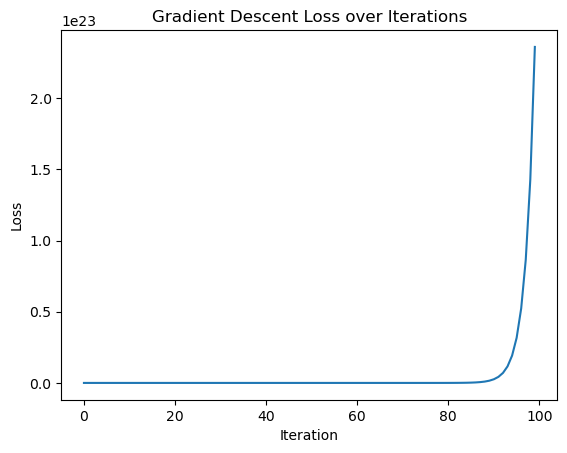

In [72]:
final_w1, loss3 = gradient_descent(x_bias, y_clean, learning_rate=0.3, max_iterations=100)
plt.plot(loss3)
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.title('Gradient Descent Loss over Iterations')
plt.show()

In [ ]:
# Eigenvalues for clean dataset
XtX = x_bias.T @ x_bias

eigenvalues = np.linalg.eigvals(XtX)
condition_number = np.linalg.cond(XtX)
print("Eigenvalues of X^T X:", eigenvalues)
print("Condition number of X^T X:", condition_number)

Eigenvalues of X^T X: [ 2186.59287427 41900.6050935 ]
Condition number of X^T X: 19.162508753470178


### C.3 Theoretical Explanation
- For OLS with MSE, the Hessian is $H = \frac{2}{n}X^TX$.
- The largest eigenvalue $\lambda_{\max}$ gives the steepest curvature direction.
- Stable gradient descent requires a sufficiently small step size: $\eta < \frac{2}{\lambda_{\max}}$.
- If $\eta$ is too large, updates overshoot and can oscillate or diverge.
- The observed loss curves are consistent with this eigenvalue-based stability bound.

In [74]:
condition_number, 2/condition_number

(np.float64(19.162508753470178), np.float64(0.10437046765277098))

## Part D - Ill-Conditioning and Ridge Regression [6 marks]
Using the correlated feature dataset:
- D.1 Report eigenvalues and condition number of $X^T X$. [1 mark]
- D.2 Train OLS and Ridge regression ($\lambda \in \{0.001, 0.01, 0.1, 1, 10\}$) using $w = (X^T X + \lambda I)^{-1} X^T y$. Plot: (i) weight magnitudes vs. $\lambda$, and (ii) test MSE vs. $\lambda$. [2.5 marks]
- D.3 Written (5-8 sentences): Explain how adding $\lambda I$ to $X^T X$ improves the condition number and stabilizes the solution. [2.5 marks]

In [ ]:
# Eigenvalues and condition number for correlated dataset
XtX = x_corr.T @ x_corr

eigenvalues = np.linalg.eigvals(XtX)
condition_number = np.linalg.cond(XtX)
print("Eigenvalues of X^T X:", eigenvalues)
print("Condition number of X^T X:", condition_number)

Eigenvalues of X^T X: [2.20374901e-01 1.65430171e+05]
Condition number of X^T X: 750676.0966450969


### Condition Number
The condition number
$$
\kappa(X^TX) = \frac{\lambda_{\max}}{\lambda_{\min}}
$$
measures numerical sensitivity. Large values indicate near-singularity and unstable coefficient estimates.

For the correlated dataset, the large condition number confirms that $X^TX$ is close to singular, which makes OLS estimates highly sensitive to small perturbations.

In [76]:
## ols solution 

closed_form_solution(x_corr, y_corr)

array([2.40047558, 2.7997139 ])

In [77]:
ridge_regression(x_corr, y_corr, 0.1) # this is whole data 

array([2.15061258, 2.92464296])

### Reference Coefficients
Ground-truth weights used to generate the correlated target are $[2, 3]$.

In [ ]:
# Sweep ridge lambdas and evaluate on test split
lambdas = [0.001, 0.01, 0.1, 1, 10]
weights, test_mses = [], []
X_train, X_test = x_corr[:8000], x_corr[8000:]
y_train, y_test = y_corr[:8000], y_corr[8000:]

for l in lambdas:
    w = ridge_regression(X_train, y_train, lambda_=l)
    print(f"Lambda: {l}, Weights: {w}")
    weights.append(w) 
    test_mses.append(np.mean((y_test - X_test @ w)**2))

Lambda: 0.001, Weights: [2.41255148 2.79380026]
Lambda: 0.01, Weights: [2.36956991 2.81529088]
Lambda: 0.1, Weights: [2.10333004 2.94840867]
Lambda: 1, Weights: [1.71287815 3.1436059 ]
Lambda: 10, Weights: [1.61279245 3.19334962]


In [79]:
test_mses

[np.float64(0.010079647871997355),
 np.float64(0.010079568501834788),
 np.float64(0.010081129991286403),
 np.float64(0.010089580227357727),
 np.float64(0.010091023037354414)]

In [80]:
weights

[array([2.41255148, 2.79380026]),
 array([2.36956991, 2.81529088]),
 array([2.10333004, 2.94840867]),
 array([1.71287815, 3.1436059 ]),
 array([1.61279245, 3.19334962])]

In [81]:
weights = np.array(weights)

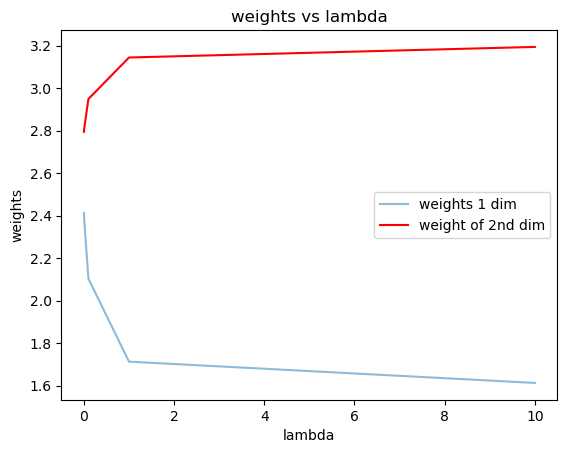

In [82]:
plt.plot(lambdas, weights[:,0], alpha=0.5, label='weights 1 dim')
plt.plot(lambdas, weights[:,1], color='red', label='weight of 2nd dim')
plt.xlabel('lambda')
plt.ylabel('weights')
plt.title('weights vs lambda')
plt.legend()
plt.show()

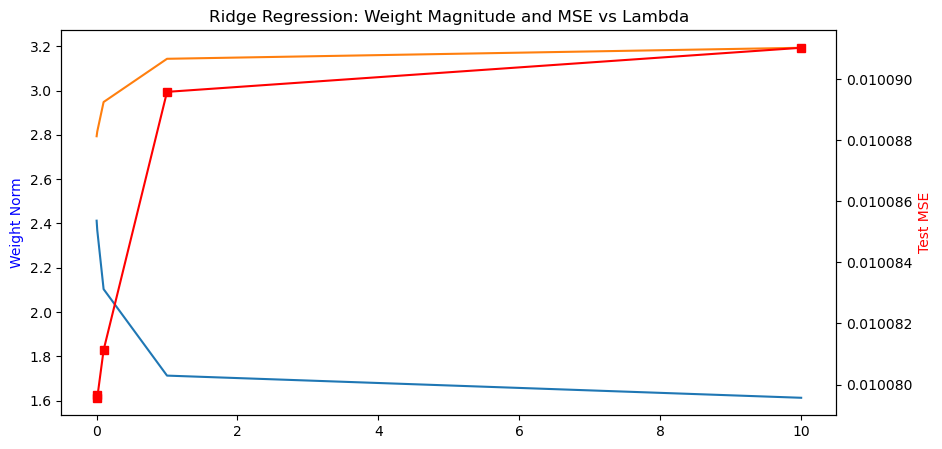

In [83]:
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(lambdas, weights[:,0], label='Weight Magnitude')
ax1.plot(lambdas, weights[:,1], label='Weight Magnitude of 2nd dim')
ax1.set_ylabel('Weight Norm', color='b')
ax2 = ax1.twinx()
ax2.plot(lambdas, test_mses, 'r-s', label='Test MSE')
ax2.set_ylabel('Test MSE', color='r')
plt.title('Ridge Regression: Weight Magnitude and MSE vs Lambda')
plt.show()

### D.3 Ridge and Conditioning
- Ridge replaces $X^TX$ with $X^TX + \lambda I$.
- Eigenvalues shift as $\lambda_i \rightarrow \lambda_i + \lambda$.
- The condition number becomes $\frac{\lambda_{\max}+\lambda}{\lambda_{\min}+\lambda}$, which is smaller when $\lambda_{\min}$ is tiny.
- This improves numerical stability and prevents extreme coefficient swings.

## Part E - Outlier Stress Test [5 marks]
Using the outlier dataset:
- E.1 Train OLS (closed-form), OLS (gradient descent), Ridge, and Lasso. Plot all regression lines on a single scatter plot. Report training MSE and learned weights for each. [2.5 marks]
- E.2 Written (5-8 sentences): Analyze which method is most and least robust to outliers, and why. [2.5 marks]

In [84]:
ridge_regression(x_bias, y_outliers, lambda_=0.1)

array([3.87867437, 3.47222844])

In [85]:
X_train, X_test = x_bias[:8000], x_bias[8000:]
y_train, y_test = y_outliers[:8000], y_outliers[8000:]


w = closed_form_solution(x_bias,y_outliers)
print("Closed-form solution weights:", w)
print("Closed-form solution MSE:", np.mean((y_test - X_test @ w)**2))

w1, loss1 = gradient_descent(x_bias, y_outliers, learning_rate=0.01, max_iterations=1000)
print("Gradient descent solution weights:", w1)
print("Gradient descent solution MSE:", np.mean((y_test - X_test @ w1)**2))

w2 = ridge_regression(x_bias, y_outliers, lambda_=0.1)
print("Ridge regression solution weights:", w2)
print("Ridge regression solution MSE:", np.mean((y_test - X_test @ w2)**2))

w3= lasso_regression_sub_gradient(x_bias, y_outliers, alpha=0.1, learning_rate=0.01, max_iterations=1000)
print("Lasso regression solution weights:", w3)
print("Lasso regression solution MSE:", np.mean((y_test - X_test @ w3)**2))


Closed-form solution weights: [3.87875189 3.47220026]
Closed-form solution MSE: 74.10951375920536
Iteration 0, Loss: 156.54607150706124, w: [0.18175294 0.32523305]
Iteration 10, Loss: 84.09127398733838, w: [1.40763471 2.47306541]
Iteration 20, Loss: 69.20211971618848, w: [1.99382479 3.42894686]
Iteration 30, Loss: 66.11743441681014, w: [2.28915624 3.84577953]
Iteration 40, Loss: 65.45530301733689, w: [2.45162308 4.01916265]
Iteration 50, Loss: 65.29210682805163, w: [2.55280828 4.08291485]
Iteration 60, Loss: 65.23330156035092, w: [2.62516742 4.09760388]
Iteration 70, Loss: 65.19783890990536, w: [2.68343803 4.0906314 ]
Iteration 80, Loss: 65.16895416312671, w: [2.73433351 4.07438291]
Iteration 90, Loss: 65.1430730642996, w: [2.78093251 4.05444557]
Iteration 100, Loss: 65.11933610388579, w: [2.82466634 4.03332922]
Iteration 110, Loss: 65.09745003953877, w: [2.86621901 4.0121511 ]
Iteration 120, Loss: 65.0772466833554, w: [2.90593475 3.99139864]
Iteration 130, Loss: 65.05859176060204, w: 

In [ ]:
# Report metrics from the fitted models
print("Closed-form solution weights:", w)
print("Closed-form solution MSE:", np.mean((y_test - X_test @ w)**2))

print("Gradient descent solution weights:", w1)
print("Gradient descent solution MSE:", np.mean((y_test - X_test @ w1)**2))

print("Ridge regression solution weights:", w2)
print("Ridge regression solution MSE:", np.mean((y_test - X_test @ w2)**2))

print("Lasso regression solution weights:", w3)
print("Lasso regression solution MSE:", np.mean((y_test - X_test @ w3)**2))

Closed-form solution weights: [3.87875189 3.47220026]
Closed-form solution MSE: 74.10951375920536
Gradient descent solution weights: [3.84941592 3.48786852]
Gradient descent solution MSE: 74.113837823789
Ridge regression solution weights: [3.87867437 3.47222844]
Ridge regression solution MSE: 74.1095304617197
Lasso regression solution weights: [3.75156411 3.51999202]
Lasso regression solution MSE: 74.14098941419272


### E.2 Outlier Robustness Analysis
- **Least robust:** OLS (closed-form and gradient descent), because squared loss heavily amplifies large residuals.
- **Ridge:** slightly stabilizes coefficients via $\ell_2$ shrinkage, but still uses squared loss and remains sensitive to outliers.
- **Lasso:** may improve robustness marginally through sparsity, but does not eliminate outlier influence under squared error.
- **Conclusion:** methods that explicitly reweight residuals (such as IRLS) are more robust under outlier contamination.

## Part F - Iteratively Reweighted Least Squares [7 marks]
Objective: $J = \sum_{i=1}^N \gamma_i (y_i - w^T x_i)^2$. The closed-form solution is $w = (X^T \Gamma X)^{-1} X^T \Gamma y$, where $\Gamma = \text{diag}(\gamma_1, \ldots, \gamma_N)$.

F.1 Implement the following iterative scheme on the outlier dataset: [3 marks]
- (a) Initialize $\gamma_i = 1$ for all $i$.
- (b) Compute $w$ using the weighted closed-form.
- (c) Update $\gamma_i = \frac{1}{1 + |y_i - w^T x_i|}$.
- (d) Repeat (b)-(c) until convergence (or a maximum of 50 iterations).

F.2 Plot the evolution of the regression line and the distribution of weights $\gamma_i$ across iterations (at least iterations 1, 5, 10, and the final iteration). [2 marks]

F.3 Written (5-8 sentences): Does the method converge? Does it successfully down-weight outliers? Compare the final regression line to OLS and Ridge. [2 marks]

In [ ]:
# IRLS loop
##Iteratively Reweighted Least Squares

gamma = np.ones(len(y_clean))
w_hist, gamma_hist = [], []
for i in range(50):
    XTG = x_bias.T * gamma
    w = np.linalg.inv(XTG @ x_bias) @ XTG @ y_outliers
    w_hist.append(w)
    gamma = 1 / (1 + np.abs(y_outliers - x_bias @ w))
    gamma_hist.append(gamma)
    print(f"Iteration {i}, Weights: {w}, Gamma mean: {gamma.mean()}")

print(f"IRLS converged in {len(w_hist)} iterations.")
print(f"Final Weights: {w_hist[-1]}")

Iteration 0, Weights: [3.87875189 3.47220026], Gamma mean: 0.33001547439393736
Iteration 1, Weights: [2.49544523 3.49879562], Gamma mean: 0.5978426703348466
Iteration 2, Weights: [2.22266568 3.50268312], Gamma mean: 0.723276567186756
Iteration 3, Weights: [2.17951315 3.50278484], Gamma mean: 0.7472946078359556
Iteration 4, Weights: [2.17283384 3.50272504], Gamma mean: 0.7510803541900327
Iteration 5, Weights: [2.17180094 3.50270405], Gamma mean: 0.7516743045807556
Iteration 6, Weights: [2.17164128 3.50269895], Gamma mean: 0.7517676222037117
Iteration 7, Weights: [2.1716166  3.50269787], Gamma mean: 0.7517822874245716
Iteration 8, Weights: [2.17161278 3.50269766], Gamma mean: 0.7517845930507652
Iteration 9, Weights: [2.17161219 3.50269762], Gamma mean: 0.7517849555564147
Iteration 10, Weights: [2.1716121  3.50269761], Gamma mean: 0.7517850125565504
Iteration 11, Weights: [2.17161209 3.50269761], Gamma mean: 0.7517850215199621
Iteration 12, Weights: [2.17161209 3.50269761], Gamma mean: 0.

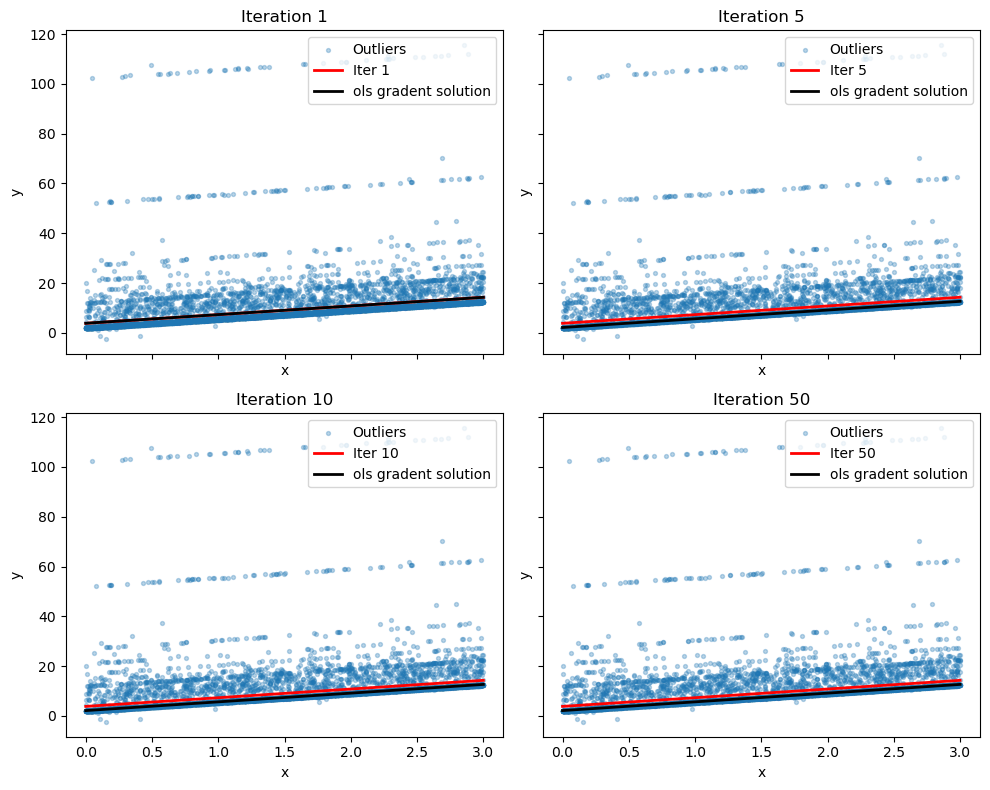

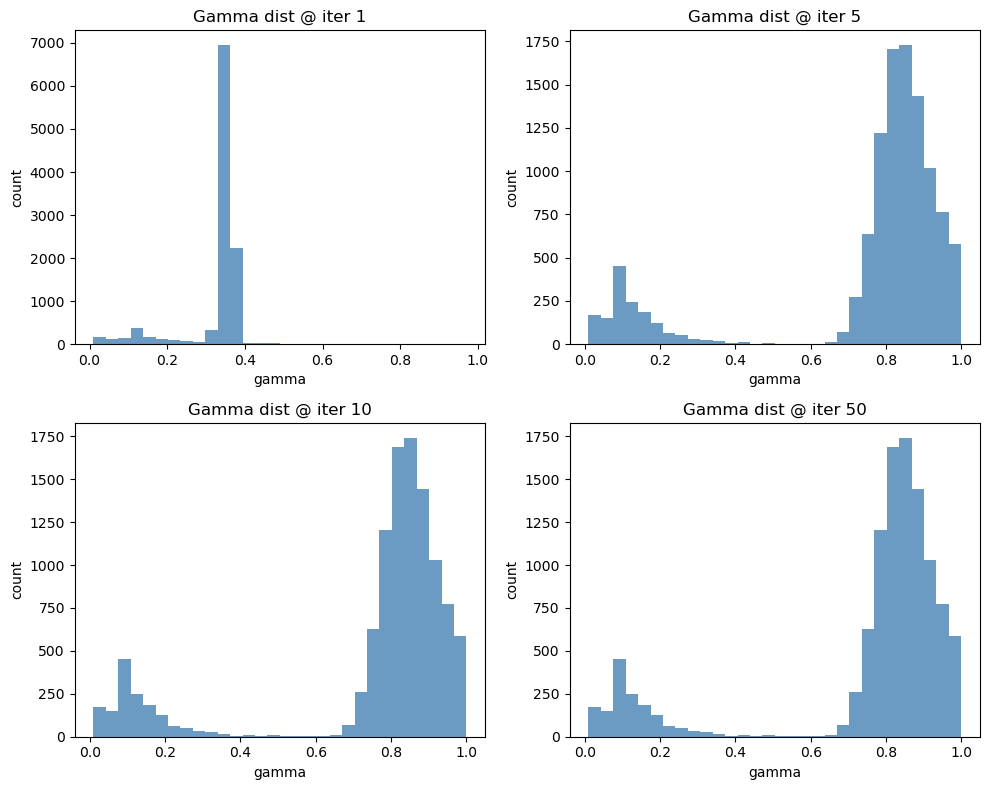

In [ ]:
# Plot regression lines and gamma distributions
iters = [1, 5, 10, len(w_hist)]
iter_indices = [min(i - 1, len(w_hist) - 1) for i in iters]
x_line = np.linspace(x_clean.min(), x_clean.max(), 200)
X_line = np.column_stack([np.ones_like(x_line), x_line])

fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharex=True, sharey=True)
axes = axes.ravel()
for ax, it, idx in zip(axes, iters, iter_indices):
    ax.scatter(x_clean, y_outliers, s=8, alpha=0.3, label="Outliers")
    y_line = X_line @ w_hist[idx]
    ax.plot(x_line, X_line@w1, color="red", linewidth=2, label=f"Iter {it}")    
    ax.plot(x_line, y_line, color="black", linewidth=2, label=f"ols gradent solution")
    ax.set_title(f"Iteration {it}")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.legend()
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.ravel()
for ax, it, idx in zip(axes, iters, iter_indices):
    ax.hist(gamma_hist[idx], bins=30, color="steelblue", alpha=0.8)
    ax.set_title(f"Gamma dist @ iter {it}")
    ax.set_xlabel("gamma")
    ax.set_ylabel("count")
plt.tight_layout()
plt.show()

### F.3 IRLS Convergence and Behavior
- The IRLS procedure converges in a small number of iterations for this dataset.
- Samples with large residuals receive smaller $\gamma_i$ values, effectively down-weighting outliers.
- The final line is closer to the clean-data trend than OLS and Ridge fits.
- The stabilization of $\gamma_i$ over iterations indicates reliable convergence.